# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [3]:
STUDENT_NAME = 'Басараб Дмитрій Богданович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 1      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 1: Львів, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [4]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [5]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [6]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_львів


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [7]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [8]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    # ----- ВАШ КОД: живий запит -----
    
    start = time.time()
    start_bytes = cache_bytes()
    g = clean(getter())
    print(g)
    g.to_parquet(path,index = False)
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                            'передано_МБ': round((cache_bytes() - start_bytes) / 1e6, 3),
                            'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                            'секунд': round(time.time() - start, 3)}
    return g
    # 1) запам'ятайте cache_bytes() і час ДО виклику getter()
    # 2) викличте getter(), проженіть результат через clean(), збережіть у path
    # 3) запишіть у COST[name] спосіб 'живий запит', записів, передано_МБ,
    #    файл_МБ і секунд
    #raise NotImplementedError('напишіть гілку живого запиту')

In [9]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 148.4 км²


In [10]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 50607 | ребер 145124


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.
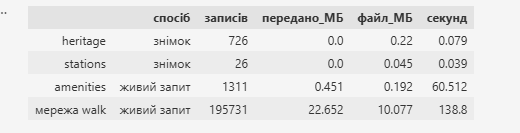

In [11]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.029,1.275
heritage,знімок,726,0.0,0.22,0.079
stations,знімок,26,0.0,0.045,0.049
amenities,знімок,1311,0.0,0.192,0.087
мережа walk,знімок,195731,0.0,10.077,0.352


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [12]:
# ----- ВАШ КОД -----
mask = (heritage["historic"].notna()) | (heritage["tourism"] == "museum")
cand = heritage[mask & heritage["name"].notna()]  # лишіть тільки ті, що мають name
cand = cand.reset_index(drop=True)
print(cand[["historic", "tourism"]])

print("усього у шарі heritage :", len(heritage))
print("підходять за тегами    :", len(heritage[mask]))
print("з них мають name       :", len(cand))

     historic tourism
0    memorial     NaN
1    memorial     NaN
2    memorial     NaN
3    memorial     NaN
4    memorial     NaN
..        ...     ...
438   railway     NaN
439   railway     NaN
440   railway     NaN
441  memorial     NaN
442  memorial     NaN

[443 rows x 2 columns]
усього у шарі heritage : 726
підходять за тегами    : 543
з них мають name       : 443


In [13]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial         174
tomb              53
wayside_cross     38
yes               21
house             18
vehicle           13
monument          12
ruins             10
railway_car       10
railway            7

=== tourism ===
tourism
museum        51
attraction     9
artwork        2

типи геометрії: {'Point': 330, 'Polygon': 106, 'LineString': 7}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [14]:
metric = cand.to_crs(32635)

cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

# ----- ВАШ КОД -----
wiki_cols = ['wikidata', 'wikipedia']
# Перевіряємо наявність наявних колонок у вашому датафреймі
existing_wiki = [col for col in wiki_cols if col in cand.columns]
cand['wiki'] = cand[existing_wiki].notna().any(axis=1)
name_cols = [c for c in heritage.columns if "name" in c.lower()]
cand['n_lang']   =  cand[name_cols].notna().sum(axis=1)
cand['signal_tourism_historic'] = (
    cand['tourism'].isin(['museum', 'gallery']) | cand['historic'].notna()
).astype(int)

cand['rank_name'] = cand['n_lang'].rank(pct=True, method='min')
cand['rank_wiki'] = cand['wiki'].rank(pct=True, method='min')
cand['rank_tourism_historic'] = cand['signal_tourism_historic'].rank(pct=True, method='min')


w_name = 0.35             
w_wiki = 0.40              
w_tourism_historic = 0.25   

# Обчислюємо фінальну колонку "цінність"
cand['score'] = (
    cand['rank_name'] * w_name +
    cand['rank_wiki'] * w_wiki +
    cand['rank_tourism_historic'] * w_tourism_historic
)

# Сортуємо датафрейм за рейтингом від найкращих до найгірших
cand = cand.sort_values(by='score', ascending=False)


print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
cand

кандидатів   : 443
мають wiki   : 87


,element,id,geometry,artwork_type,name,name:de,name:en,name:pl,name:uk,statue,...,building:part,wikipedia:uk,area_m2,wiki,n_lang,signal_tourism_historic,rank_name,rank_wiki,rank_tourism_historic,score
355,way,166224256,"POLYGON ((24.02568 49.8371, 24.02587 49.83719,...",NaN,Львівська національна галерея мистецтв,NaN,Lviv National Art Gallery,Lwowska Galeria Sztuki,Львівська національна галерея мистецтв,NaN,...,NaN,NaN,1157.389270,True,12,1,1.000000,0.805869,0.002257,0.672912
342,way,131582482,"POLYGON ((24.05737 49.8305, 24.05726 49.83053,...",NaN,Меморіал львівських орлят,Friedhof der Lemberger Adlerjungen,Cemetery of Eaglets,Cmentarz Orląt Lwowskich,Меморіал львівських орлят,NaN,...,NaN,NaN,18391.703436,True,10,1,0.997743,0.805869,0.002257,0.672122
338,way,40887654,"POLYGON ((24.03259 49.84214, 24.03255 49.84222...",NaN,Кам'яниця Корнякта,NaN,Koriniakt Palace (The Royal Town House),"Kamienica Królewska ""Mały Wawel""",Кам'яниця Корнякта,NaN,...,NaN,NaN,579.401407,True,8,1,0.995485,0.805869,0.002257,0.671332
359,way,170023137,"POLYGON ((24.02707 49.83814, 24.02713 49.83817...",NaN,Палац Потоцьких,Potocki-Palast,Potocki Palace,Pałac Potockich,Палац Потоцьких,NaN,...,NaN,NaN,1351.056547,True,7,1,0.981941,0.805869,0.002257,0.666591
347,way,151409890,"POLYGON ((24.03439 49.84324, 24.03457 49.84272...",NaN,Королівський арсенал,Königliches Arsenal,Royal Arsenal,Arsenał Królewski,Королівський арсенал,NaN,...,NaN,NaN,1132.640612,True,7,1,0.981941,0.805869,0.002257,0.666591
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
285,node,12086275008,POINT (24.06913 49.78932),NaN,Пам'ятний хрест на згадку про скасування панщи...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.000000,False,1,1,0.002257,0.002257,0.002257,0.002257
192,node,6292835443,POINT (24.03276 49.865),NaN,Скульптура Богородиці,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.000000,False,1,1,0.002257,0.002257,0.002257,0.002257
308,node,13074177093,POINT (24.02676 49.86486),NaN,8 стація,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.000000,False,1,1,0.002257,0.002257,0.002257,0.002257
34,node,1992282779,POINT (24.05284 49.8318),NaN,Felicia Łochowska,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.000000,False,1,1,0.002257,0.002257,0.002257,0.002257


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [15]:
N_SMALL, N_LARGE = 10, 30

# ----- ВАШ КОД -----
top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)
top_naive

overlap = len(pd.merge(top_naive,top10))
print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                       'за площею': list(top_naive['name'])}))

перетин: 3 з 10


,за вашим критерієм,за площею
0,Львівська національна галерея мистецтв,Личаківський цвинтар
1,Меморіал львівських орлят,Марсове поле
2,Кам'яниця Корнякта,Меморіал львівських орлят
3,Палац Потоцьких,"Австрійський форт (Fort ""Zjawienska Gora"")"
4,Королівський арсенал,Меморіал Українським Січовим стрільцям та воїн...
5,"Національний музей ""Тюрма на Лонцького""",Австрійський форт
6,Личаківський цвинтар,Львівський музей історії релігії
7,Національний музей у Львові,Національний музей у Львові
8,Львівський Державний Природознавчий Музей,Польський військовий меморіал
9,Іванові Франку,Будинок вчених


не завжди великі за площею обєкти мають велику історичну цінність

### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [16]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

# ----- ВАШ КОД: виведіть знайдені пари з назвами -----

pairs = close_pairs(top_score)
for pair in pairs:
    print(top_score.iloc[pair[0]]["name"], "---" ,top_score.iloc[pair[1]]["name"],pair[2])

Локальна залізниця Львів — Підгайці --- Локальна залізниця Львів — Підгайці 3.9079332199135695
Львівський історичний музей --- Музей скла 20.20796972852233
Кам'яниця Корнякта --- Львівський історичний музей 26.036011681736372
Локальна залізниця Львів — Підгайці --- Локальна залізниця Львів — Підгайці 41.90015832266399
Локальна залізниця Львів — Підгайці --- Локальна залізниця Львів — Підгайці 42.25092791529282
Кам'яниця Корнякта --- Музей скла 44.30260401004013
Львівський історичний музей --- Музей міста 50.493386633216225


є три записи локальної залізниці- видаляєм два
ЛІМ і музей міста це різні тому лишаєм
а музей скла це підвідділ ЛІМ тому зливаємо
камяниця корнятка це місце де є лім тому зливаємо

---
## 4. Старт: вокзал, і прив'язка точок до графа

In [17]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 26
                 name  railway building
0               Рудно  station      NaN
1            5-й Парк     halt      NaN
2    Львів-Коновальця     halt      NaN
3   Львів-Персенківка  station      NaN
4          Зубрівська     halt      NaN
5             Сонячна  station      NaN
6             Паркова  station      NaN
7      Львів-Клепарів  station      NaN
8       Княгині Ольги     halt      NaN
9    Львів-Городоцька     halt      NaN
10              Рясна     halt      NaN
11            Скнилів  station      NaN


In [18]:
# ----- ВАШ КОД -----
station = stations[stations["name"]=="Львів-Головний"]  # один рядок із stations: головний залізничний вокзал
print('старт:', station['name'].iloc[0])

старт: Львів-Головний


In [19]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 50607 вузлів, 143747 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [20]:
def check_snap(points, ids, dist, label):
    # ----- ВАШ КОД -----
    #s = snap(points)
    ids, dist = snap(points)
    print(len(ids))
    print(len(np.unique(ids)))
    print(np.median(dist))
    print(np.max(dist))
    if len(np.unique(ids)) < len(ids):
        # Беремо назви об'єктів з переданого стовпця label
        names = points[label].values
        
        # Створюємо табличку для пошуку дублікатів
        df_temp = pd.DataFrame({'point_name': names, 'node_id': ids})
        
        # Групуємо точки за вузлами і шукаємо ті, де більше 1 точки
        grouped = df_temp.groupby('node_id')['point_name'].apply(list)
        collapsed = grouped[grouped.apply(len) > 1]
        
        print("\nНазви точок, що злиплися (прив'язалися до одного вузла):")
        for node_id, pts in collapsed.items():
            print(f" • До вузла {node_id} прикріплені точки: {pts}")

a,b = snap(make_points(stations))
print(make_points(stations).columns)
check_snap(make_points(stations),a,b,"name")
len(stations)


Index(['name', 'geometry'], dtype='str')
27
25
18.954787069084265
61.78541648225918

Назви точок, що злиплися (прив'язалися до одного вузла):
 • До вузла 1833125882 прикріплені точки: ['СТАРТ: Львів-Головний', 'Львів-Головний']
 • До вузла 8812556191 прикріплені точки: ['Скнилів', nan]


26

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [21]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    """Матриця прямих віддалей у метрах між усіма парами точок."""
    # Переводимо в метричну проєкцію (як у вашій функції snap, наприклад, 32635)
    # щоб розрахунки були точно в метрах, а не в градусах
    points_m = points.to_crs(32635)
    
    k = len(points_m)
    E = np.zeros((k, k))
    
    # Рахуємо відстань по прямій між кожною парою точок geometry
    for i, p_start in enumerate(points_m.geometry):
        for j, p_end in enumerate(points_m.geometry):
            E[i, j] = p_start.distance(p_end)
            
    return E

def detour_factor(D, E):
    """Медіана відношення дорога / пряма, по скінченних парах."""
    # 1. Ділимо матрицю доріг (D) на матрицю прямих відстаней (E)
    # Щоб уникнути попередження про ділення на нуль на діагоналі (де відстань 0/0),
    # використовуємо np.divide з feature 'where' або ігноруємо діагональ
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio_matrix = D / E
    
    # 2. Робимо матрицю плоскою (перетворюємо в одновимірний масив)
    ratios_flat = ratio_matrix.flatten()
    
    # 3. Фільтруємо значення:
    # - прибираємо нескінченність np.inf (пари точок, між якими немає проїзду графом)
    # - прибираємо NaN (діагональні елементи, де було 0 / 0)
    valid_ratios = ratios_flat[np.isfinite(ratios_flat) & ~np.isnan(ratios_flat)]
    
    # 4. Знаходимо медіану серед усіх правильних пар
    if len(valid_ratios) > 0:
        detour_median = np.median(valid_ratios)
    else:
        detour_median = 1.0  # Дефолтне значення, якщо немає скінченних пар
        
    return detour_median


**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [22]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

11
11
22.326142683842193
47.240469528887964
матриця за 2.731 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.19


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [23]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))
import math
def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    n = len(D)
    current = 0
    path = [current]
    
    # Створюємо множину невідвіданих точок (всі від 1 до n-1)
    unvisited = set(range(1, n))
    
    while unvisited:
        # Шукаємо таку точку серед НЕВІДВІДАНИХ, для якої відстань D[current, node] є мінімальною
        next_node = min(unvisited, key=lambda node: D[current, node])
        
        path.append(next_node)
        unvisited.remove(next_node) # Викреслюємо її
        current = next_node         # Робимо її поточною для наступного кроку
        
    path.append(0) # Повертаємося наприкінці в початкову точку
    return path

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best_tour = tour.copy()
    best_length = tour_length(D, best_tour)
    improved = True
    
    while improved:
        improved = False
        n = len(best_tour)
        
        # Перебираємо всі можливі пари ребер для розвороту внутрішньої ділянки
        for i in range(1, n - 2):
            for j in range(i + 1, n - 1):
                # Створюємо новий маршрут, розгортаючи ділянку від i до j включно
                new_tour = best_tour[:]
                new_tour[i:j+1] = reversed(best_tour[i:j+1])
                
                new_length = tour_length(D, new_tour)
                
                # Якщо новий маршрут виявився коротшим, фіксуємо його
                if new_length < best_length:
                    best_tour = new_tour
                    best_length = new_length
                    improved = True
                    break # Виходимо до внутрішнього циклу, щоб почати пошук спочатку
            if improved:
                break # Повертаємося на початок while
                
    return best_tour


In [24]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [25]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))


nn10 = nearest_neighbour(D10)
print(nn10)
op10 = two_opt(D10, nn10)
print(op10)
ex10, L_opt = held_karp(D10)
print(ex10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

[0, 6, 1, 4, 10, 8, 9, 3, 5, 7, 2, 0]
[0, 10, 8, 9, 3, 5, 7, 2, 4, 1, 6, 0]
[0, 10, 8, 9, 3, 5, 7, 2, 4, 1, 6, 0]
найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [26]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,13392,6.36
2-opt,12591,0.00
Held-Karp (точний),12591,0.00



оптимальний порядок:
   0. СТАРТ: Львів-Головний
   1. Іванові Франку
   2. Національний музей у Львові
   3. Львівський Державний Природознавчий Музей
   4. Кам'яниця Корнякта
   5. Королівський арсенал
   6. Личаківський цвинтар
   7. Меморіал львівських орлят
   8. Палац Потоцьких
   9. Львівська національна галерея мистецтв
  10. Національний музей "Тюрма на Лонцького"
  11. СТАРТ: Львів-Головний

довжина: 12.59 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [27]:
# ----- ВАШ КОД: таблиця зростання -----
n = [11,16,21,26,31]

df = pd.DataFrame(n)
df["cells"] = 2**(df[0]-1) * (df[0]-1)
df["Gb"] = df["cells"]*8/1024**3
df

,0,cells,Gb
0,11,10240,0.000076
1,16,491520,0.003662
2,21,20971520,0.156250
3,26,838860800,6.250000
4,31,32212254720,240.000000


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.


Оперативна память не має 240 гб

In [28]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'name')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

31
28
22.326142683842193
63.62224208964129

Назви точок, що злиплися (прив'язалися до одного вузла):
 • До вузла 9889644523 прикріплені точки: ['Локальна залізниця Львів — Підгайці', 'Локальна залізниця Львів — Підгайці', 'Локальна залізниця Львів — Підгайці']
 • До вузла 13803598476 прикріплені точки: ["Кам'яниця Корнякта", 'Львівський історичний музей']
коефіцієнт обходу: 1.18
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    29311 м
2-opt            :    26018 м  за 0.066 с  (коротше на 11.2%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

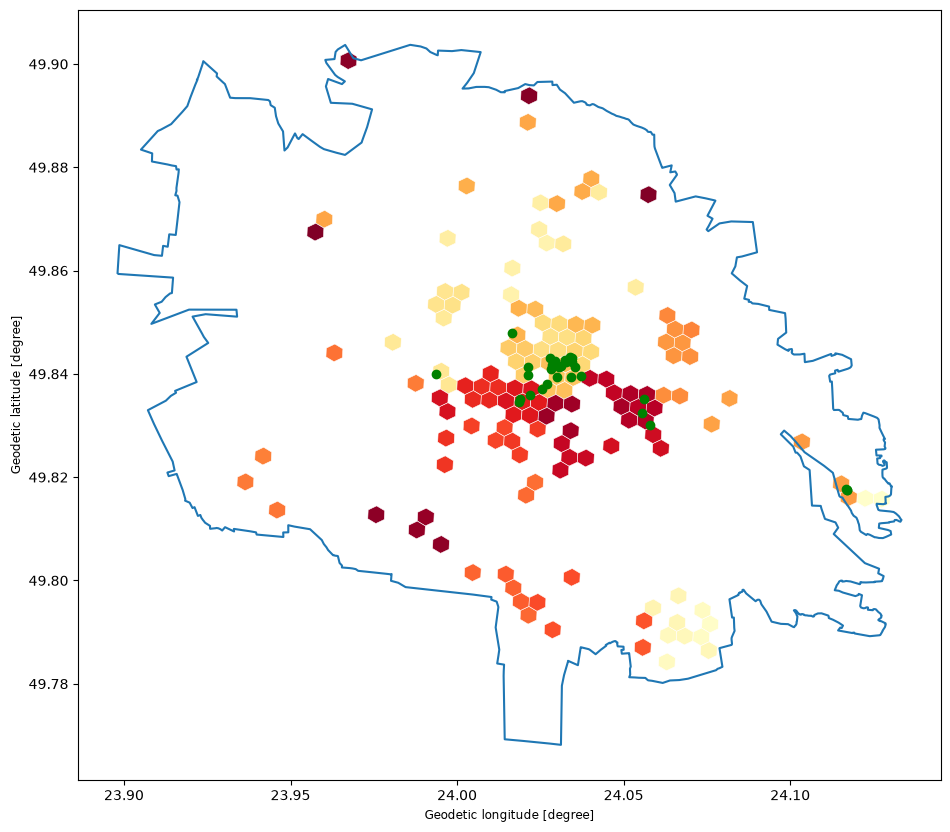

In [29]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

# ----- ВАШ КОД -----
#print(cand)
#print(make_points(cand).geometry)
fig, ax = plt.subplots(figsize=(12, 10))
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in make_points(cand).geometry[1:]]
dens = cand.groupby('h3').size().reset_index(name='density')
dens
hexes = gpd.GeoDataFrame(
    dens, 
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in dens['h3']], 
    crs='EPSG:4326'
)
hexes.plot(ax=ax, cmap='YlOrRd',legend = True,  edgecolor='white', linewidth=0.4,
                         legend_kwds={'label': 'закладів у комірці', 'shrink': 0.6})
boundary.boundary.plot(ax=ax)
make_points(top_score).plot(ax=ax,color="green")
# побудуйте карту

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [30]:
# ----- ВАШ КОД -----
top_score = top_score.to_crs(32635)
amenities = amenities.to_crs(32635)
res = top_score.sjoin_nearest(amenities,    how="inner", 
    distance_col="distance_m"  )
res[["name_left","name_right","distance_m"]]


,name_left,name_right,distance_m
0,Львівська національна галерея мистецтв,NaN,17.568263
1,Меморіал львівських орлят,NaN,4.922667
2,Кам'яниця Корнякта,Каса Леоне,1.828794
3,Палац Потоцьких,Корівка,51.777746
4,Королівський арсенал,NaN,0.807343
5,"Національний музей ""Тюрма на Лонцького""",PamPuh,65.367181
6,Личаківський цвинтар,NaN,0.000000
6,Личаківський цвинтар,NaN,0.000000
7,Національний музей у Львові,Da Vinci,26.192441
8,Львівський Державний Природознавчий Музей,BubbleWaffle,6.571792


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [59]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords



# ----- ВАШ КОД: 
real_path = route_coords(nn10,ids10)
straight_line = [(pts10.geometry.iloc[i].y, pts10.geometry.iloc[i].x) for i in tour]
straight_line
start = pts10.geometry.iloc[0]
end = pts10.geometry.iloc[len(pts10)-1]
print(end)
fmap = folium.Map(location=[start.y, start.x], zoom_start=14, tiles=BASEMAP)
folium.Marker([start.y, start.x]).add_to(fmap)
folium.Marker([end.y,end.x]).add_to(fmap)
folium.PolyLine(real_path).add_to(fmap)
folium.PolyLine(straight_line,color="red").add_to(fmap)
fmap
#folium.Map(, tiles=BASEMAP)
#, дві PolyLine, маркери з номерами -----
fmap.save('lr5_маршрут.html')
fmap

POINT (24.02118 49.8397118)


---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [57]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (17.2 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [60]:
REPORT = '''
1.Взяв всі історичні + музеї

усього у шарі heritage : 726
підходять за тегами    : 543
з них мають name       : 443
2. я вибрав чи є стаття, скільки має перекладів і ячи призначений для відвідування, кожному призначивсши коеф важливості
3.2 означає 
4.1ю18 коеф обгоду показує шо приблизно однакові прямі шдляхи
5.11 відсотків
6.Заважає недоступна память 240 гб
7.нічого з ними не зробив

Декларація про використання ШІ:
користувалася ШІ-помічником Gemini.
Де саме:
- для пояснення суті завдань і коду, який був у ноутбуці.
- для написання коду.
'''
print(REPORT)


1.Взяв всі історичні + музеї

усього у шарі heritage : 726
підходять за тегами    : 543
з них мають name       : 443
2. я вибрав чи є стаття, скільки має перекладів і ячи призначений для відвідування, кожному призначивсши коеф важливості
3.2 означає 
4.1ю18 коеф обгоду показує шо приблизно однакові прямі шдляхи
5.11 відсотків
6.Заважає недоступна память 240 гб
7.нічого з ними не зробив

Декларація про використання ШІ:
користувалася ШІ-помічником Gemini.
Де саме:
- для пояснення суті завдань і коду, який був у ноутбуці.
- для написання коду.

